# 12 첫 모델 학습 — A/B × 로지스틱/XGBoost

실제 로컬 학습 결과를 읽고 재검증합니다. XGBoost는 CUDA, 로지스틱은 CPU를 사용했습니다. H600/L60·보수적 라벨·시간 순서 분할이며 holdout은 사용하지 않았습니다. 전체 재학습은 `scripts/train_stage2.py`로 실행합니다. 이 Notebook은 자동 재학습하지 않습니다.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np, pandas as pd
from IPython.display import display,Image
from src.common import TABLES,CFG
assert Path(sys.executable).resolve()==Path(CFG['python']).resolve()
OUT=ROOT/'outputs/stage2'
print('실제 실행:',sys.executable)
contract=json.loads((OUT/'source_contract.json').read_text(encoding='utf-8'))
assert contract['holdout_scored'] is False
display(contract)

실제 실행: C:\Users\fl27\anaconda3\envs\phm2018\python.exe


{'pretraining_manifest_sha256': '2d31bcaf67ba433c32682ca194b94ba41912b103d6253ab153c26bffe91301bd',
 'compute_config': {'training_device': 'cuda:0',
  'training_tree_method': 'hist',
  'training_cpu_threads': 12,
  'io_threads': 4,
  'parallel_training_trials': 1,
  'initial_max_bin': 128,
  'host_memory_budget_gib': 12,
  'gpu_reserve_mib': 1024,
  'gpu_training_smoke_test_required': True,
  'silent_cpu_fallback_allowed': False,
  'note': '사용자 CUDA 우선 지시 반영. GPU 실제 학습 검증은 2단계에서 수행. 드라이버/패키지 자동 변경 없음.'},
 'xgboost_version': '3.2.0',
 'holdout_scored': False,
 'model_selection_status': 'FIRST_COMPARISON_NOT_FINAL_SELECTION'}

## 1. 경보 로직의 독립 검증과 실제 CUDA 학습

시험 점수는 경보 검증에만 썼고 모델 성능에 섞지 않았습니다. CUDA 장치 이름만 확인한 것이 아니라 실제 smoke 학습 후 booster 장치를 확인했습니다.

독립 검사 통과: 27


{'success': True,
 'device': 'cuda:0',
 'rows': 50000,
 'positive': 1000,
 'trees': 20,
 'seconds': 0.32410287857055664,
 'source': '실제 train 후보에서 seed42로 선택; 검증 점수로 사용하지 않음'}

,run_id,feature_set,model,device,train_rows,train_positive,validation_all_rows,validation_known_rows,validation_positive,encoded_features,iterations,train_seconds,AP_known,ROC_AUC_known,log_loss_known,artifact_roundtrip_passed
0,A_logistic,A,logistic,cpu,916051,2332,1061290,25266,776,424,94,2.758614,0.058390,0.376102,0.209334,True
1,A_xgboost,A,xgboost,cuda:0,916051,2332,1061290,25266,776,424,27,0.680361,0.170344,0.439372,0.176272,True
2,B_logistic,B,logistic,cpu,664285,1981,745401,17398,627,446,130,5.354463,0.070042,0.394552,0.211608,True
3,B_xgboost,B,xgboost,cuda:0,664285,1981,745401,17398,627,446,2,1.236616,0.067437,0.468656,0.209911,True


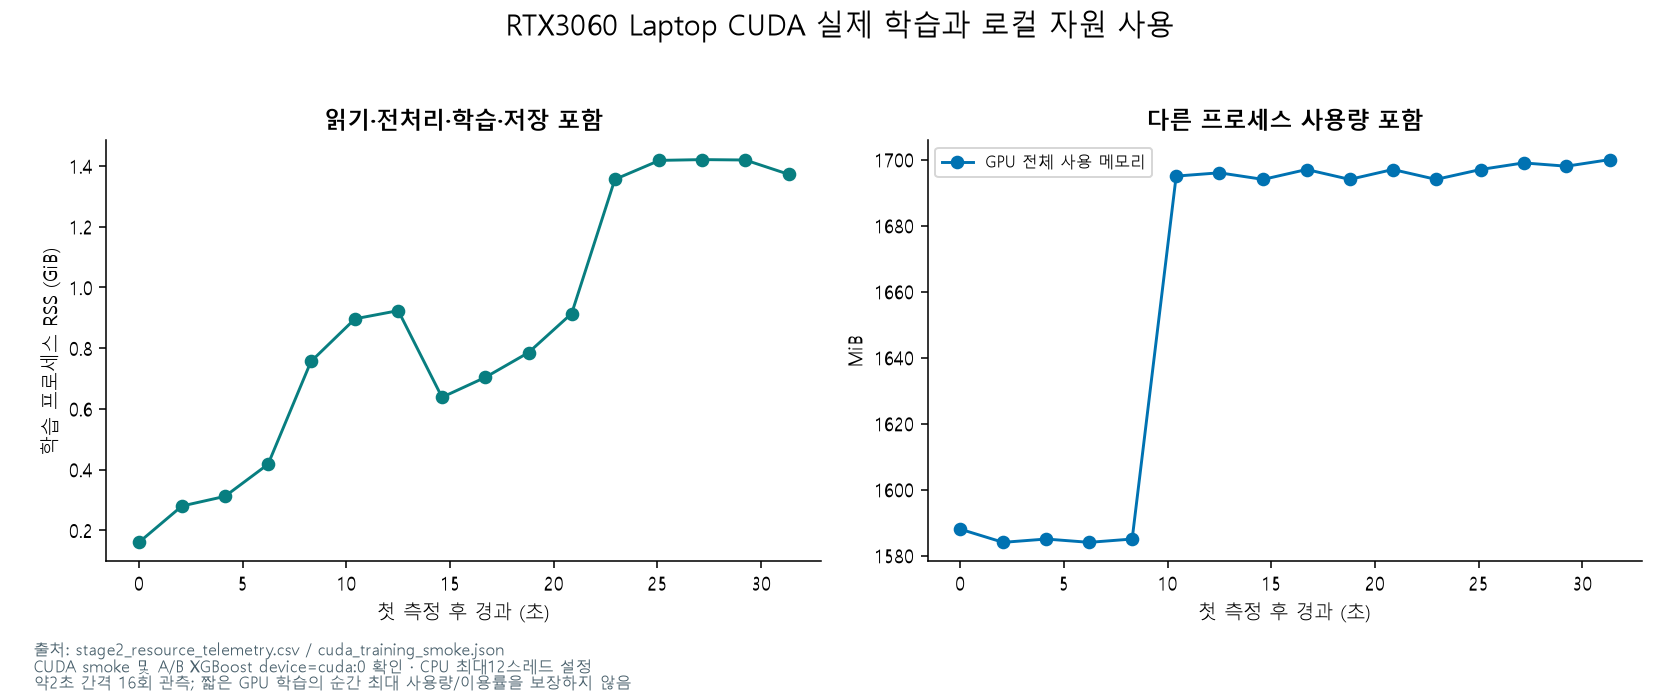

In [2]:
audit=json.loads((ROOT/'outputs/validation/alarm_independent_audit.json').read_text(encoding='utf-8'))
assert all(c['passed'] for c in audit['checks'])
print('독립 검사 통과:',len(audit['checks']))
smoke=json.loads((OUT/'cuda_training_smoke.json').read_text(encoding='utf-8'))
assert smoke['success'] and smoke['device']=='cuda:0'
display({k:v for k,v in smoke.items() if k!='booster_config'})
runs=pd.read_parquet(TABLES/'stage2_training_summary.parquet')
assert runs[runs.model.eq('xgboost')].device.eq('cuda:0').all()
display(runs)
display(Image(filename=str(ROOT/'outputs/figures/stage2/local_resources.png')))

## 2. 분류 지표와 조기 종료

AP/ROC-AUC는 알려진 POS/NEG 후보에서만 계산합니다. XGBoost aucpr과 sklearn AP는 계산이 다릅니다. B의 이른 조기 종료 원인은 후속 실험에서 분리해야 합니다.

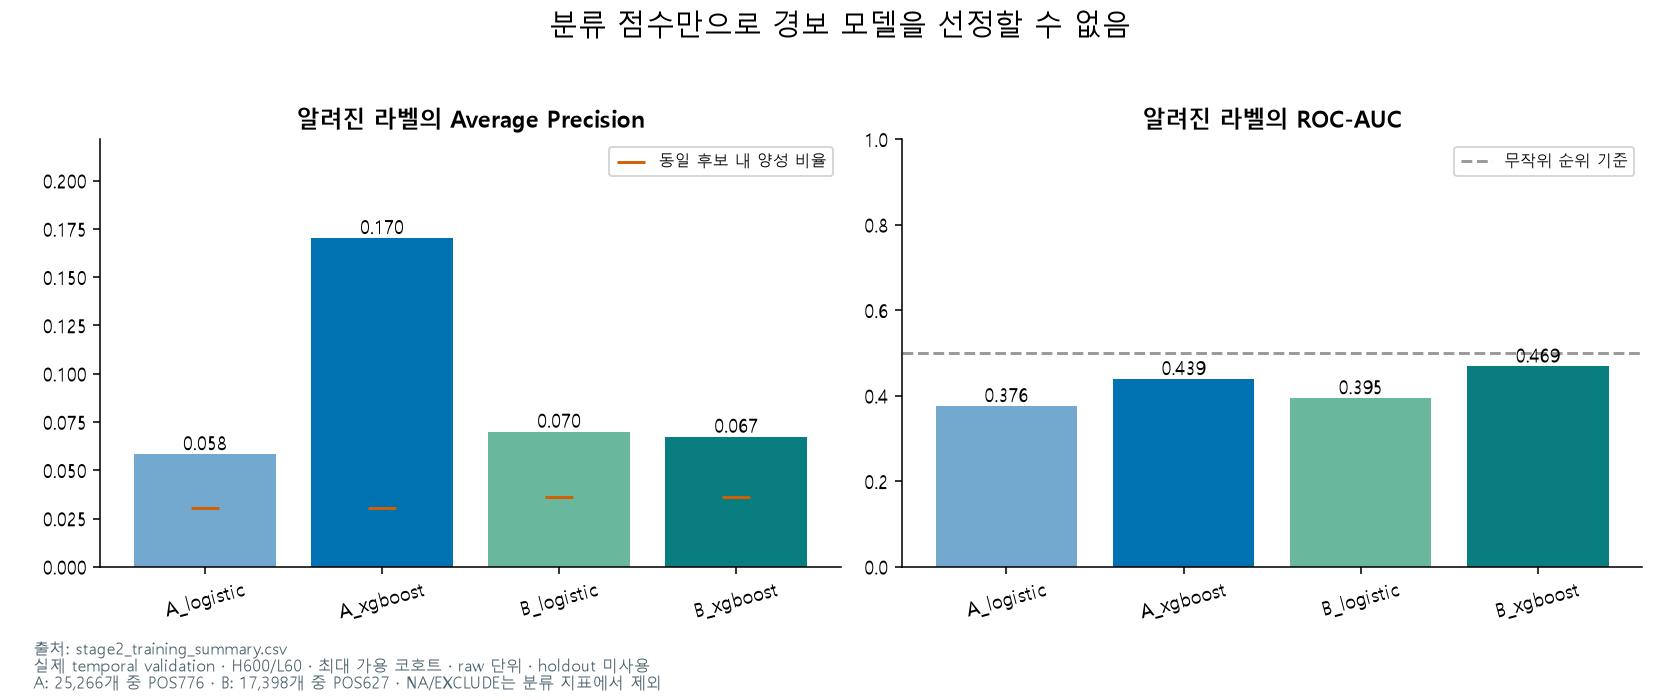

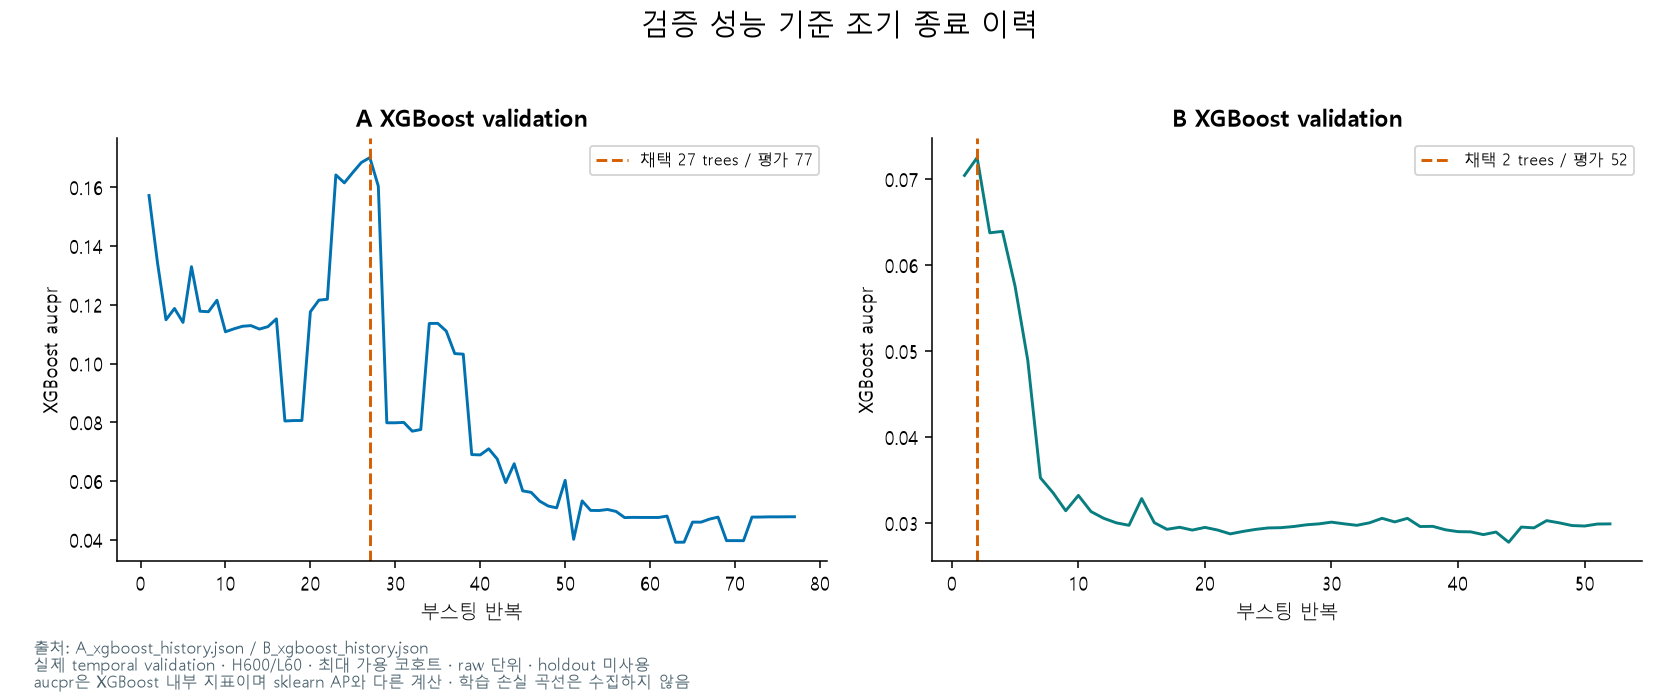

,run_id,label,rows,score_min,score_p50,score_p90,score_p99,score_max
0,A_logistic,NEG,24490,1.918720e-05,0.004383,0.102533,0.199070,0.465320
1,A_logistic,POS,776,3.382656e-05,0.002622,0.009882,0.864170,0.927042
2,A_logistic,NA,1035941,6.951296e-07,0.002179,0.009643,0.860932,0.962437
3,A_logistic,EXCLUDE,83,2.357608e-05,0.002630,0.009660,0.875399,0.926968
4,A_xgboost,NEG,24490,1.569868e-03,0.003904,0.006009,0.006009,0.006405
5,A_xgboost,POS,776,1.146401e-03,0.003371,0.006844,0.024558,0.024558
6,A_xgboost,NA,1035941,1.103271e-03,0.002932,0.005522,0.016443,0.060478
7,A_xgboost,EXCLUDE,83,1.145729e-03,0.003408,0.006325,0.013652,0.024558
8,B_logistic,NEG,16771,6.915878e-09,0.006435,0.030476,0.100041,0.303045
9,B_logistic,POS,627,6.761863e-08,0.004088,0.016725,0.936147,0.936339


In [3]:
display(Image(filename=str(ROOT/'outputs/figures/stage2/classification.png')))
display(Image(filename=str(ROOT/'outputs/figures/stage2/learning_history.png')))
display(pd.read_parquet(TABLES/'stage2_score_states.parquet'))

## 3. 전체 가용 구간의 경보 곡선

NA/EXCLUDE를 유지합니다. 오래 유지된 경보를 뒤의 예측 창에서 새 검출로 소급하지 않습니다. A/B 최대 가용 코호트가 달라 순수 특징 효과가 아닙니다.

,run_id,operating_point,threshold,detected_events,available_events,recall_recorded,recall_available,alarm_episodes,alarm_episodes_per_10000_raw,median_lead_raw
0,A_logistic,검출최대의50%,0.004036,18.0,98.0,0.077586,0.183673,43345.0,7.117730,366.0
1,A_logistic,검출최대의80%,0.002219,22.0,98.0,0.094828,0.224490,58785.0,9.653150,371.0
2,A_logistic,검출최대의100%,0.000355,27.0,98.0,0.116379,0.275510,67858.0,11.143037,348.0
3,A_xgboost,검출최대의50%,0.001103,25.0,98.0,0.107759,0.255102,63590.0,10.442184,330.0
4,A_xgboost,검출최대의80%,0.003000,34.0,98.0,0.146552,0.346939,105018.0,17.245122,362.0
5,A_xgboost,검출최대의100%,0.003000,34.0,98.0,0.146552,0.346939,105018.0,17.245122,362.0
6,B_logistic,검출최대의50%,0.004429,24.0,95.0,0.103448,0.252632,23836.0,5.663014,367.0
7,B_logistic,검출최대의80%,0.000344,29.0,95.0,0.125000,0.305263,58419.0,13.879327,352.0
8,B_logistic,검출최대의100%,0.000084,31.0,95.0,0.133621,0.326316,61767.0,14.674753,328.0
9,B_xgboost,검출최대의50%,0.003143,26.0,95.0,0.112069,0.273684,33127.0,7.870393,335.0


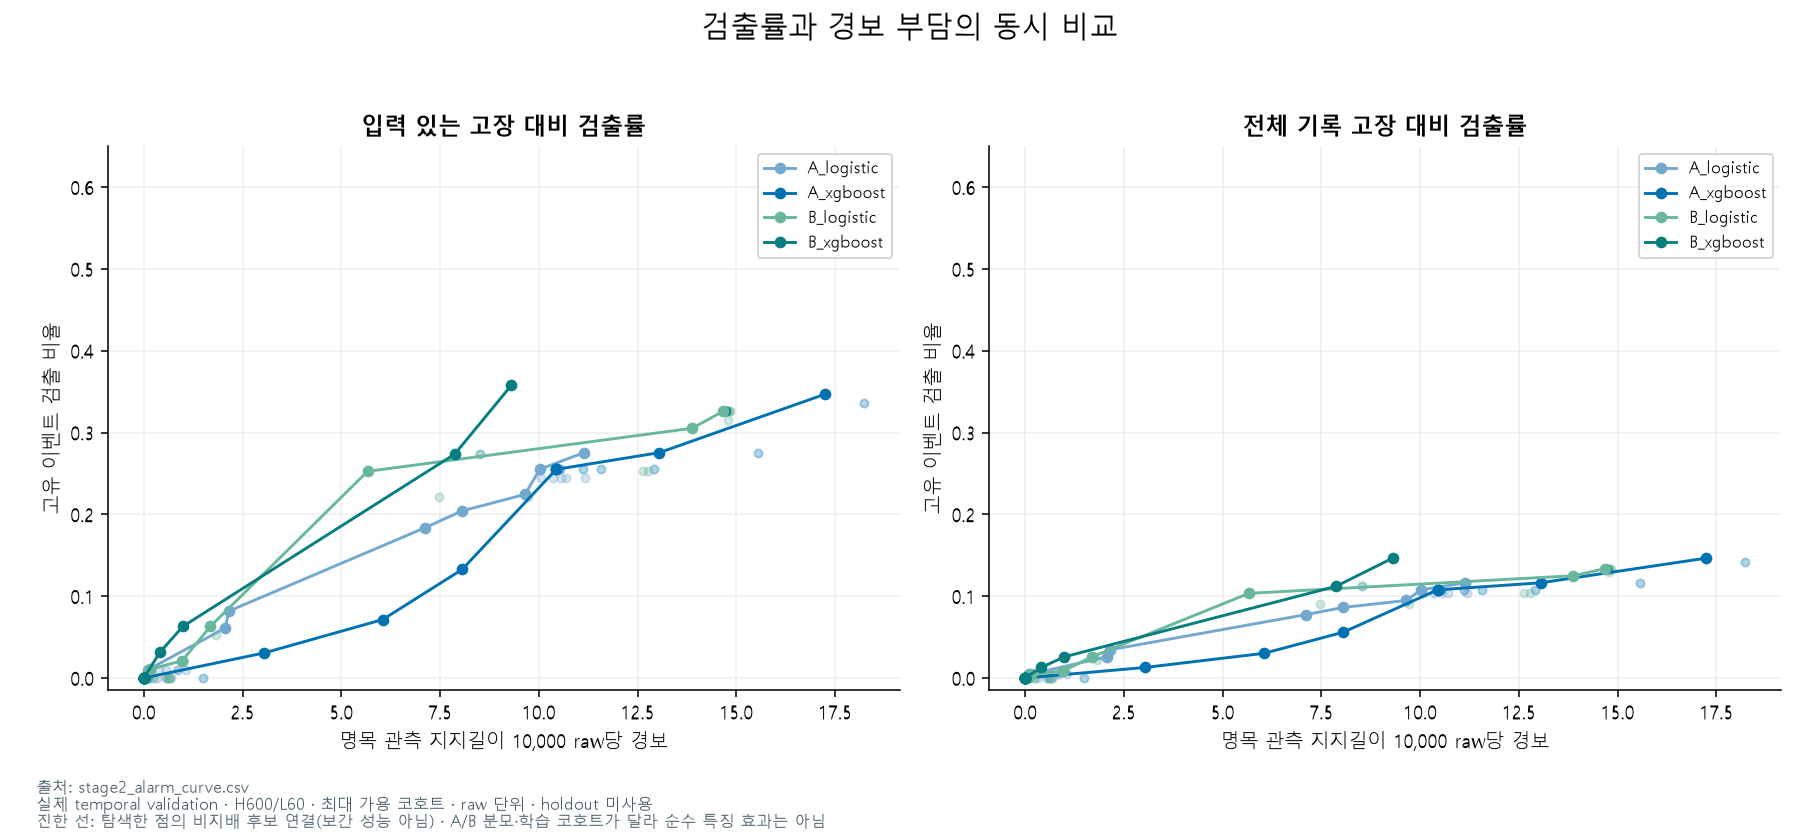

전체 임계값 후보: 99


In [4]:
curve=pd.read_parquet(TABLES/'stage2_alarm_curve.parquet')
points=pd.read_parquet(TABLES/'stage2_operating_points.parquet')
display(points[['run_id','operating_point','threshold','detected_events','available_events','recall_recorded','recall_available','alarm_episodes','alarm_episodes_per_10000_raw','median_lead_raw']])
display(Image(filename=str(ROOT/'outputs/figures/stage2/alarm_tradeoff.png')))
assert (curve.detected_events<=curve.available_events).all()
assert curve.recorded_events.eq(232).all()
print('전체 임계값 후보:',len(curve))

## 4. 미확인 경보·장비 편차·불확실성

20 Tool 군집 재표집 2,000회. 임계값 고정 조건부 구간이며 선택 낙관, 장비쌍 의존성, 이력 불완전성을 보정하지 못합니다. 미확인 경보는 확정 오경보가 아닙니다.

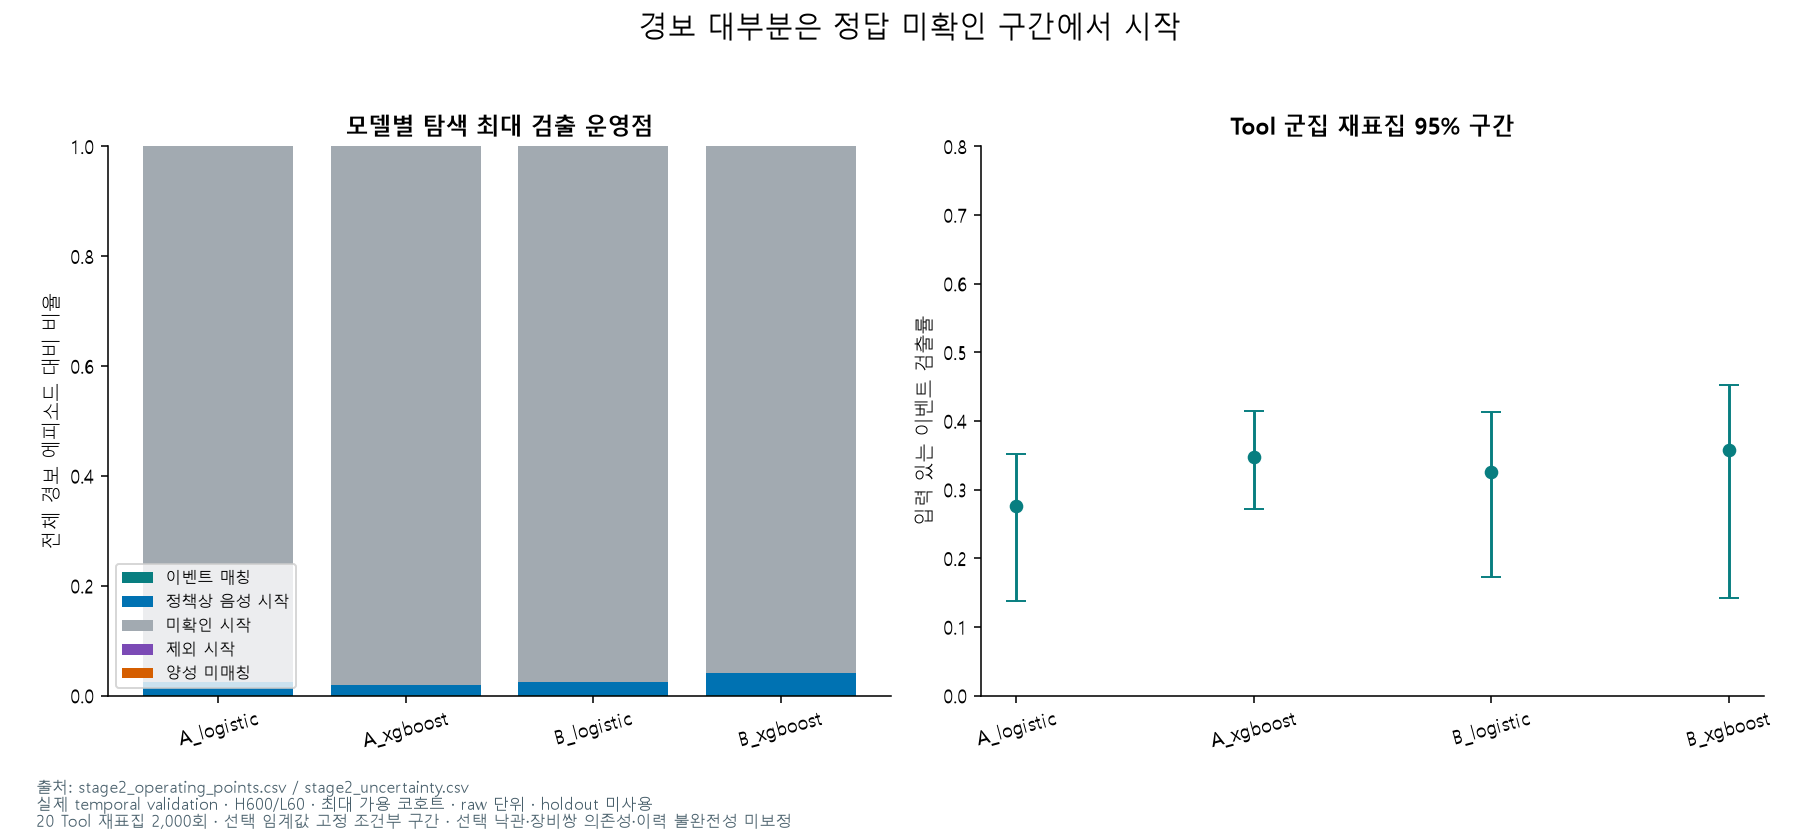

,run_id,operating_point,threshold,denominator,recall,ci_low,ci_high,bootstrap_samples,valid_bootstrap_samples,lead_p10,lead_median
0,A_logistic,검출최대의50%,0.004036,available,0.183673,0.090909,0.285714,2000,2000,117.2,366.0
1,A_logistic,검출최대의50%,0.004036,recorded,0.077586,0.043009,0.095238,2000,2000,117.2,366.0
2,A_logistic,검출최대의80%,0.002219,available,0.224490,0.150901,0.278354,2000,2000,126.8,371.0
3,A_logistic,검출최대의80%,0.002219,recorded,0.094828,0.059480,0.145171,2000,2000,126.8,371.0
4,A_logistic,검출최대의100%,0.000355,available,0.275510,0.137920,0.351150,2000,2000,176.0,348.0
5,A_logistic,검출최대의100%,0.000355,recorded,0.116379,0.067300,0.167470,2000,2000,176.0,348.0
6,A_xgboost,검출최대의50%,0.001103,available,0.255102,0.156847,0.320008,2000,2000,159.2,330.0
7,A_xgboost,검출최대의50%,0.001103,recorded,0.107759,0.067853,0.159848,2000,2000,159.2,330.0
8,A_xgboost,검출최대의80%,0.003000,available,0.346939,0.272727,0.417722,2000,2000,173.0,362.0
9,A_xgboost,검출최대의80%,0.003000,recorded,0.146552,0.109285,0.204658,2000,2000,173.0,362.0


,run_id,operating_point,Tool,detected,available,recorded
187,B_xgboost,검출최대의100%,01M01,0,0,3
188,B_xgboost,검출최대의100%,01M02,1,7,8
189,B_xgboost,검출최대의100%,02M01,1,3,9
190,B_xgboost,검출최대의100%,02M02,0,1,5
191,B_xgboost,검출최대의100%,03M01,0,3,9
192,B_xgboost,검출최대의100%,03M02,11,23,91
193,B_xgboost,검출최대의100%,04M01,0,0,3
194,B_xgboost,검출최대의100%,04M02,1,10,16
195,B_xgboost,검출최대의100%,05M01,0,1,1
196,B_xgboost,검출최대의100%,05M02,0,0,1


,rows,unknown_recipe,unknown_stage,unseen_combination
feature_set,,,,
A,1061290,73765,14782,134759
B,745401,54843,8396,96112


In [5]:
display(Image(filename=str(ROOT/'outputs/figures/stage2/alarm_uncertainty.png')))
display(pd.read_parquet(TABLES/'stage2_uncertainty.parquet'))
tool_results=pd.read_parquet(TABLES/'stage2_tool_event_results.parquet')
display(tool_results[tool_results.run_id.eq('B_xgboost') & tool_results.operating_point.eq('검출최대의100%')])
unseen=pd.read_parquet(TABLES/'stage2_unseen_process.parquet')
display(unseen.groupby('feature_set')[['rows','unknown_recipe','unknown_stage','unseen_combination']].sum())

## 5. 실제 검출·미탐 사례

원본과 저장된 전체 시계열 경보를 확대합니다. 시각·행 수는 아래 표에 있습니다.

,event_id,Tool,status,fault_time,window_start,window_end,raw_rows,score_anchors,lead_raw,threshold
0,03M02-low-8d5d3ebde91d,03M02,DETECTED,35634688.0,35633188.0,35634808.0,366,15,328.0,0.002999
1,01M02-low-1e9609701f87,01M02,MISSED,25636030.0,25634530.0,25636150.0,406,27,NaN,0.002999


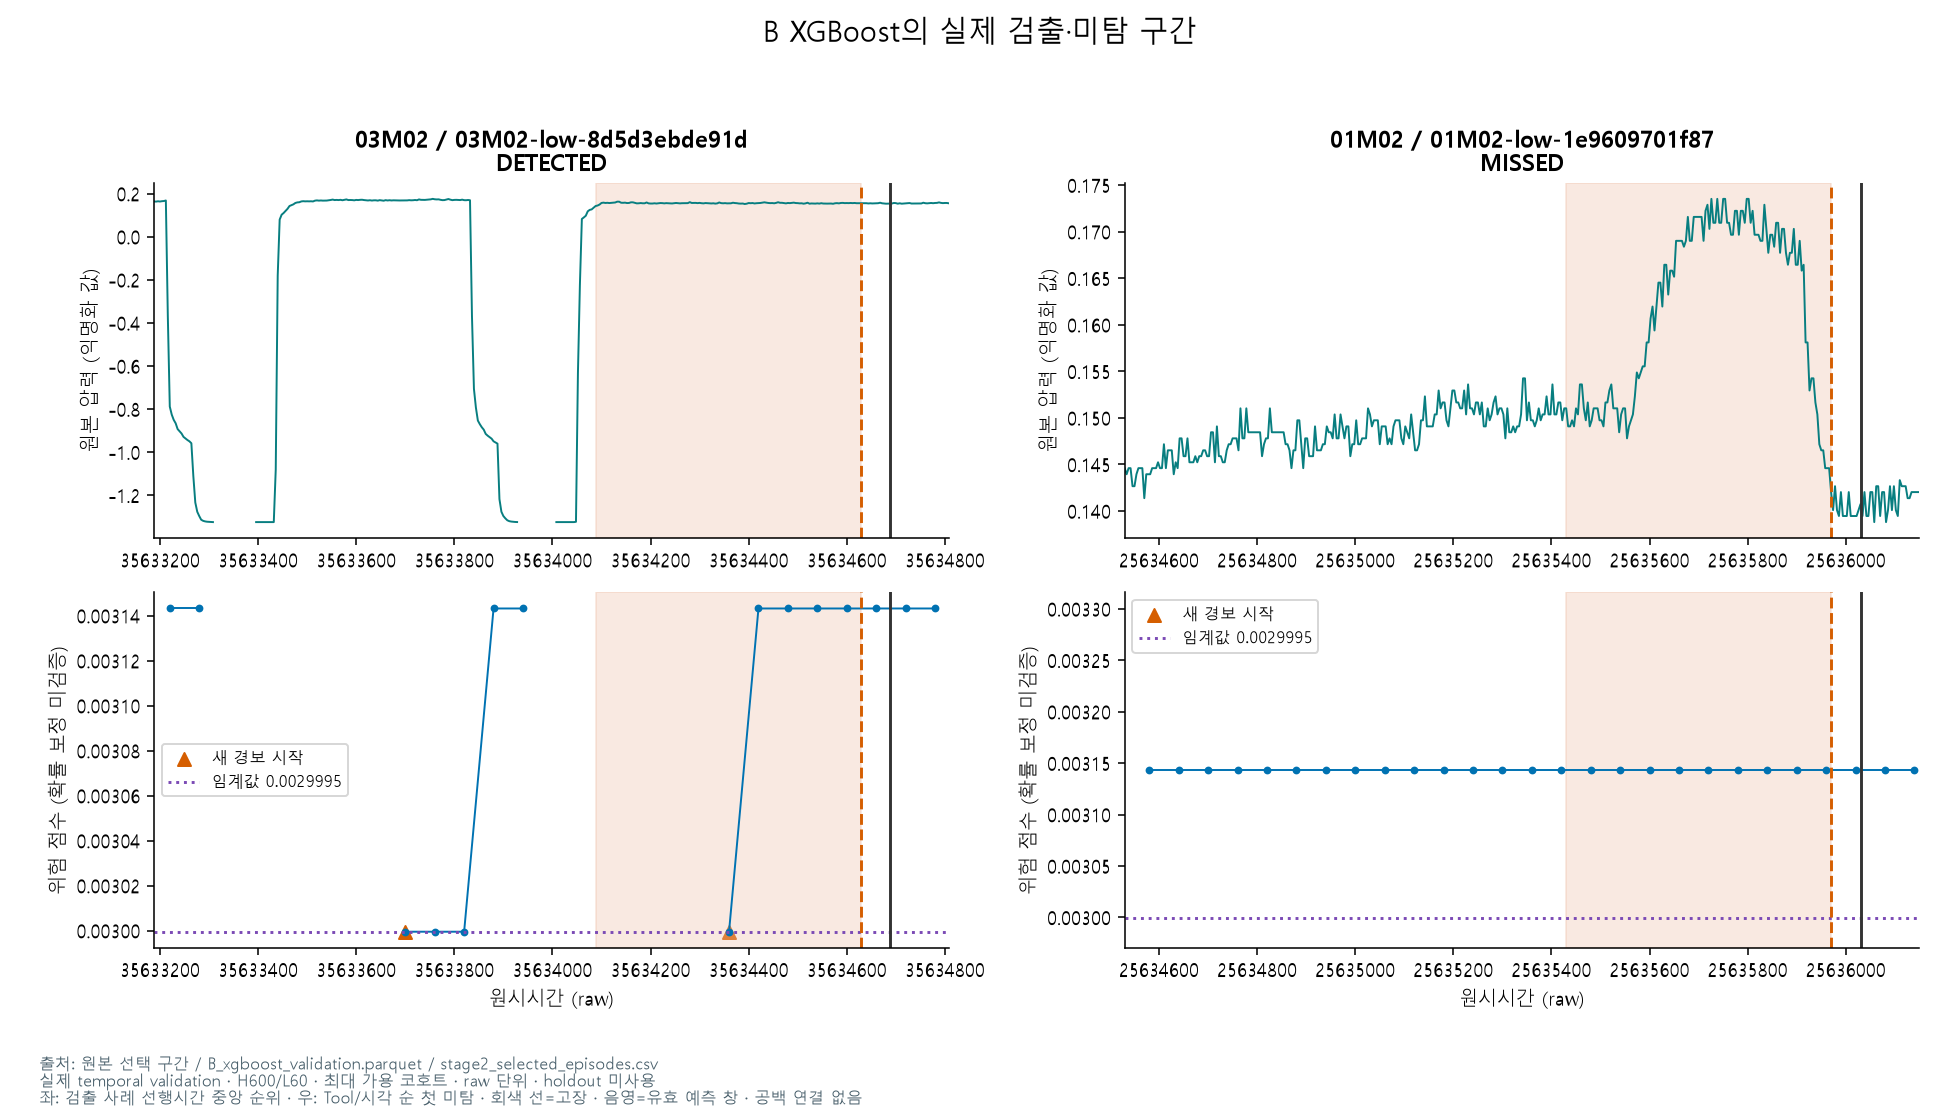

In [6]:
display(pd.read_parquet(TABLES/'stage2_example_cases.parquet'))
display(Image(filename=str(ROOT/'outputs/figures/stage2/event_examples.png')))

## 6. 저장 모델·전처리로 실제 입력 예측 재현

각 특징의 실제 validation 첫 배치에서 128행을 읽고 4개 저장 모델의 예측이 저장 점수와 일치하는지 검증합니다. 전처리는 fit하지 않고 transform만 호출합니다.

In [7]:
import joblib,xgboost as xgb
from src.pretraining import iter_scoring_batches
from src.features import schema
for family in 'AB':
    X,meta=next(iter_scoring_batches('temporal','validation',family,600))
    X=X.iloc[:128];meta=meta.iloc[:128]
    assert list(X.columns)==schema()[family]
    assert not {'time','Tool','audit_label','TTF'} & set(X)
    prep=joblib.load(OUT/f'{family}_preprocessor.joblib')
    transformed=prep.transform(X).astype('float32')
    for kind in ['logistic','xgboost']:
        rid=f'{family}_{kind}'
        model=joblib.load(OUT/(rid+'.joblib'))
        if kind=='xgboost':
            score=model.get_booster().predict(xgb.DMatrix(transformed),iteration_range=(0,model.best_iteration+1))
        else:
            score=model.predict_proba(transformed)[:,1]
        saved=pd.read_parquet(OUT/(rid+'_validation.parquet'),columns=['Tool','time','score'])
        matched=meta[['Tool','time']].merge(saved,on=['Tool','time'],how='left',validate='one_to_one')
        np.testing.assert_allclose(score,matched.score,rtol=1e-6,atol=1e-7)
        print(rid,': 저장 예측과 실제 재계산 일치',len(score),'행')

A_logistic : 저장 예측과 실제 재계산 일치 128 행


A_xgboost : 저장 예측과 실제 재계산 일치 128 행


B_logistic : 저장 예측과 실제 재계산 일치 128 행
B_xgboost : 저장 예측과 실제 재계산 일치 128 행


## 다음 실험

B XGBoost를 우선 검토하되 A/B/C 공통 코호트에서 각각 재학습해 특징 효과를 분리합니다. 이후 제한된 가중치/깊이 조정, seed 민감도, 장비 그룹 일반화, 고정 후 holdout 순으로 진행합니다. 현재 validation은 조기 종료/임계값/모델 비교에 재사용하므로 독립 성능이 아닙니다. 시간 단위·정비 종료·고장 이력 완전성은 미검증입니다.